# Sampling requirements of the numerical (m,n)-mode projection over the worldtube

The smallest fixed N_φ and the smallest N_t per radial period for which the (m,n)-modes with 0 ≤ m ≤ 20 and |n| ≤ 20 of route `numerical` reach E ≤ 10⁻⁸, at the field points of the spectre eccentric-orbit worldtube (χ = 0.5, p = 10, e = 0.3). E is measured per point: the largest mode difference divided by the largest reference mode at that point. Interior points use `src`; face points use PhiS, ∂_rPhiS and ∂_θPhiS. N_t_req and the N_φ values each meet 5 × 10⁻⁹. N_φ_pair holds together with N_t_req, N_φ_safe at the reference N_t, and N_φ_all at every N_t from N_t_req to the reference. The data come from `test/nphi_nt_map.py`.

In [1]:
import json
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator, NullFormatter

DATA = os.path.join("..", "data")
rows = pd.read_csv(os.path.join(DATA, "nphi_nt_map.csv.gz"))
summary = pd.read_csv(os.path.join(DATA, "nphi_nt_map_summary.csv"))
with open(os.path.join(DATA, "nphi_nt_map.meta.json")) as f:
    meta = json.load(f)

INK = "#52514e"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "lines.linewidth": 1.5, "lines.markersize": 4, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})
R_MIN, R_MAX = 100 / 13, 100 / 7
QUANTITIES = ["N_t_req", "Nphi_pair", "Nphi_safe", "Nphi_all"]
TITLES = {"N_t_req": "N_t", "Nphi_pair": "N_φ with N_t_req", "Nphi_safe": "N_φ at the reference N_t", "Nphi_all": "N_φ at every N_t ≥ N_t_req"}

## Run metadata

In [2]:
print("orbit (a, p, e):", meta["orbit"], " r*(p):", round(meta["rstar_p"], 6))
print("worldtube:", meta["worldtube"])
print("target", meta["target"], "per half", meta["half"], "reference test", meta["ref_tol"], "cross-check", meta["xcheck_tol"])
print(f"{meta['points']} points, wall time {meta['wall_seconds'] / 60:.1f} min, single-core {summary.seconds.sum() / 3600:.1f} h")
print(summary.groupby(["kind", "verified"]).size().rename("points").to_string())
summary[~summary.verified][["label", "N_ref", "N_t_req", "Nphi_pair", "Nphi_safe", "Nphi_all"]]

orbit (a, p, e): [0.5, 10.0, 0.3]  r*(p): 12.77594
worldtube: {'r_in': 3.4099538200381, 'r_out': 18.548766628684238, 'cos_theta': [-0.5, 0.5]}
target 1e-08 per half 5e-09 reference test 1e-09 cross-check 1e-09
232 points, wall time 40.2 min, single-core 8.0 h
kind      verified
face      True         40
interior  True        192


,label,N_ref,N_t_req,Nphi_pair,Nphi_safe,Nphi_all


## Interior: `src`

Each cell shows log₂ of the required value; `>` marks a point where no level up to the largest tried meets the target, and `*` a point whose reference failed its test (a lower bound). The radial range of the orbit lies between the dashed lines.

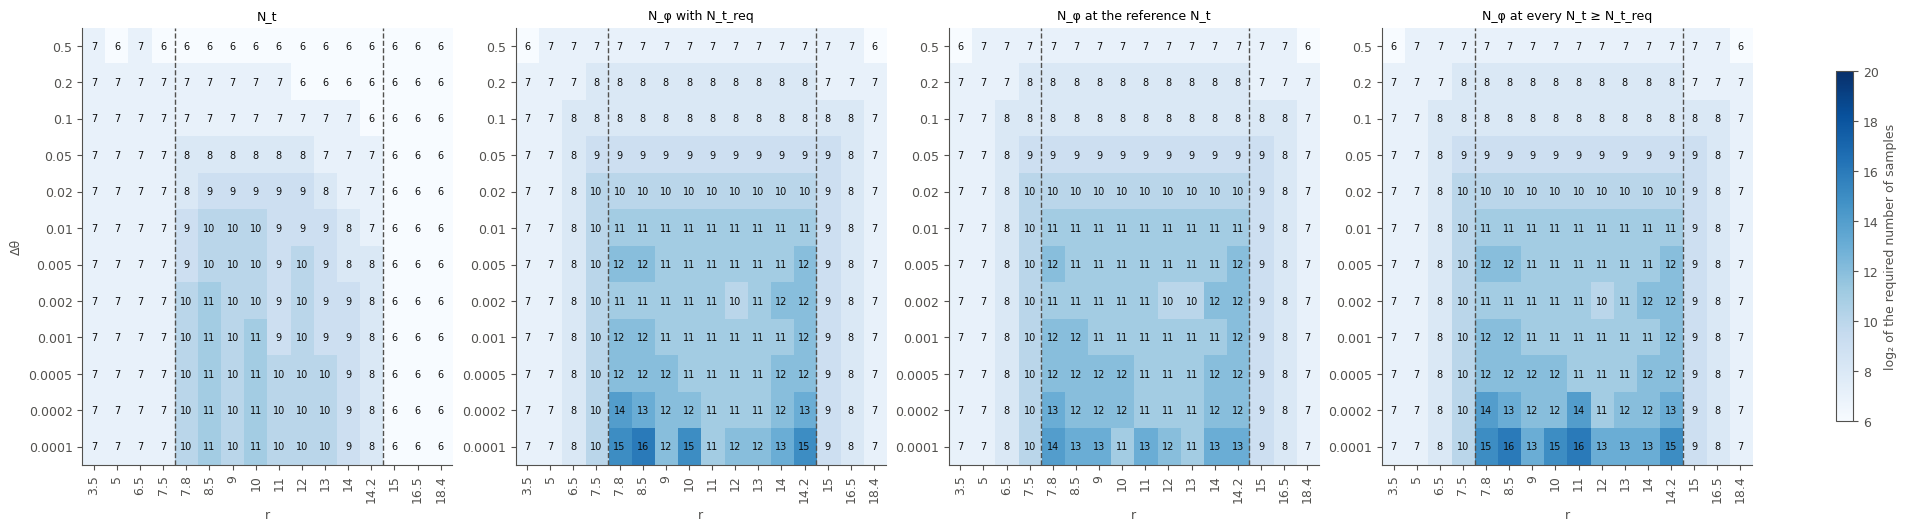

In [3]:
inner = summary[summary.kind == "interior"]
rs = sorted(inner.r.unique())
ds = sorted(inner.dth.unique(), reverse=True)
fig, axes = plt.subplots(1, 4, figsize=(19, 5.2), constrained_layout=True)
for ax, q in zip(axes, QUANTITIES):
    grid = np.full((len(ds), len(rs)), np.nan)
    for _, s in inner.iterrows():
        i, j = ds.index(s.dth), rs.index(s.r)
        if pd.notna(s[q]):
            grid[i, j] = math.log2(s[q])
        text = f"{int(round(grid[i, j]))}" if pd.notna(s[q]) else ">"
        ax.text(j, i, text + ("" if s.verified else "*"), ha="center", va="center", fontsize=7, color="#0b0b0b")
    im = ax.imshow(grid, cmap="Blues", aspect="auto", vmin=6, vmax=20)
    ax.set_xticks(range(len(rs)), [f"{r:g}" for r in rs], rotation=90)
    ax.set_yticks(range(len(ds)), [f"{d:g}" for d in ds])
    ax.grid(False)
    for x in (sum(r < R_MIN for r in rs) - 0.5, sum(r < R_MAX for r in rs) - 0.5):
        ax.axvline(x, color=INK, linestyle="--", linewidth=1)
    ax.set_title(TITLES[q], fontsize=9)
    ax.set_xlabel("r")
axes[0].set_ylabel("Δθ")
fig.colorbar(im, ax=axes, label="log₂ of the required number of samples", shrink=0.8)
plt.show()

## Faces: PhiS, ∂_rPhiS and ∂_θPhiS

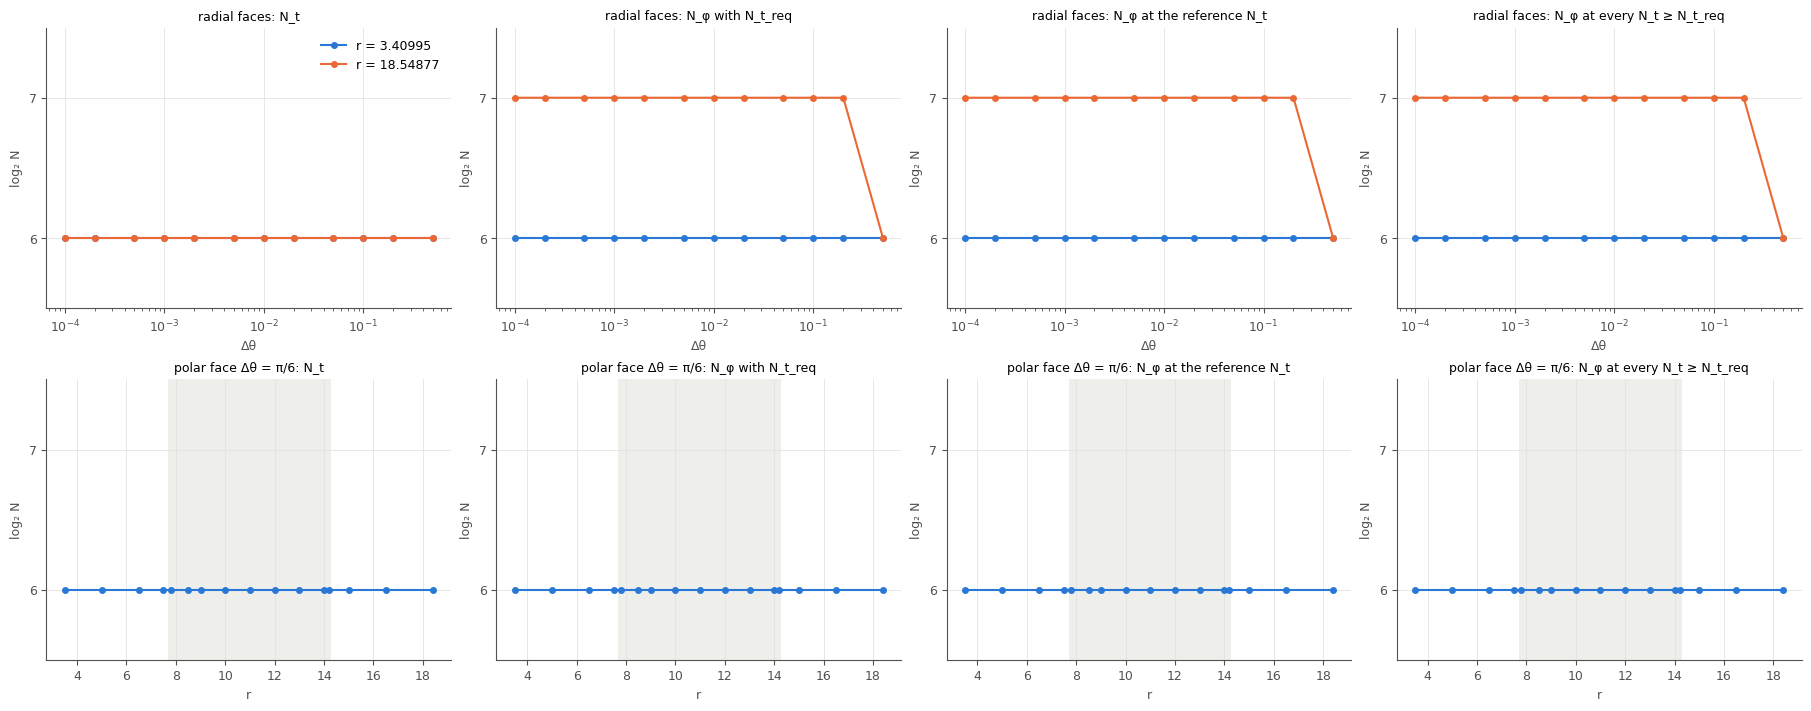

In [4]:
faces = summary[summary.kind == "face"]
polar = faces[np.isclose(faces.dth, math.pi / 6)]
radial = faces[~np.isclose(faces.dth, math.pi / 6)]
fig, axes = plt.subplots(2, 4, figsize=(18, 7), constrained_layout=True)
for j, q in enumerate(QUANTITIES):
    ax = axes[0, j]
    for k, (r, g) in enumerate(sorted(radial.groupby("r"))):
        g = g.sort_values("dth")
        ax.semilogx(g.dth, np.log2(g[q].astype(float)), "-o", color=SERIES[k], label=f"r = {r:.5f}")
    ax.set_ylim(5.5, max(7.5, ax.get_ylim()[1]))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(f"radial faces: {TITLES[q]}", fontsize=9)
    ax.set_xlabel("Δθ")
    ax.set_ylabel("log₂ N")
    ax = axes[1, j]
    g = polar.sort_values("r")
    ax.plot(g.r, np.log2(g[q].astype(float)), "-o", color=SERIES[0])
    ax.axvspan(R_MIN, R_MAX, color="#e4e3df", alpha=0.6, linewidth=0)
    ax.set_ylim(5.5, max(7.5, ax.get_ylim()[1]))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(f"polar face Δθ = π/6: {TITLES[q]}", fontsize=9)
    ax.set_xlabel("r")
    ax.set_ylabel("log₂ N")
axes[0, 0].legend(frameon=False)
plt.show()

## Ladders at four points

Top: E against N_t at the reference N_φ. Bottom: the N_φ error against the fixed N_φ, at N_t_req and at the reference N_t. The dashed line is the half target 5 × 10⁻⁹.

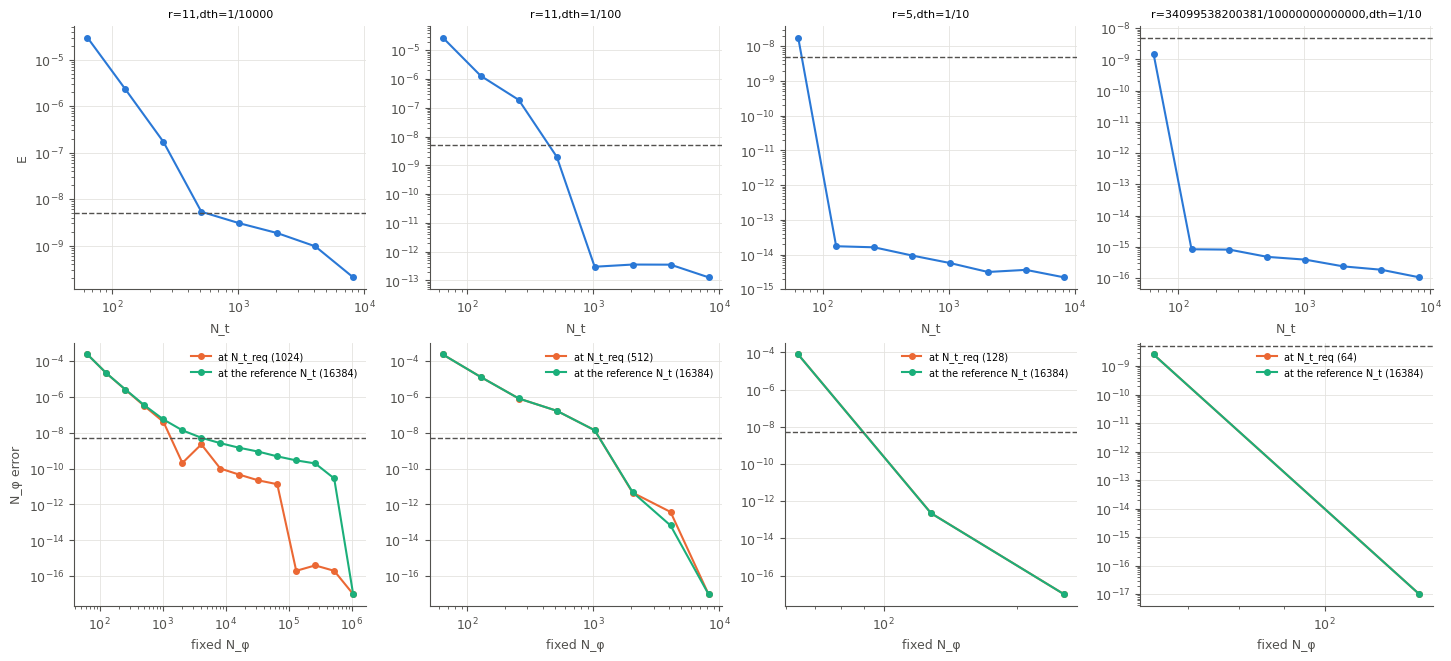

In [5]:
picks = ["r=11,dth=1/10000", "r=11,dth=1/100", "r=5,dth=1/10", "r=34099538200381/10000000000000,dth=1/10"]
picks = [p for p in picks if p in set(summary.label)]
fig, axes = plt.subplots(2, len(picks), figsize=(3.6 * len(picks), 6.5), constrained_layout=True, squeeze=False)
for j, lab in enumerate(picks):
    s = summary[summary.label == lab].iloc[0]
    g = rows[rows.label == lab]
    t = g[g.nphi_max == 0].sort_values("N_t")
    ax = axes[0, j]
    ax.loglog(t.N_t, t.E, "-o", color=SERIES[0])
    ax.axhline(meta["half"], color=INK, linestyle="--", linewidth=1)
    ax.set_title(lab, fontsize=8)
    ax.set_xlabel("N_t")
    ax = axes[1, j]
    for k, (nt, name) in enumerate(((s.N_t_req, "at N_t_req"), (s.N_ref, "at the reference N_t"))):
        if pd.notna(nt):
            p = g[(g.N_t == nt) & (g.nphi_max > 0)].sort_values("nphi_max")
            ax.loglog(p.nphi_max, p.E_phi.clip(lower=1e-17), "-o", color=SERIES[k + 1], label=f"{name} ({int(nt)})")
    ax.axhline(meta["half"], color=INK, linestyle="--", linewidth=1)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("fixed N_φ")
    ax.legend(frameon=False, fontsize=7)
axes[0, 0].set_ylabel("E")
axes[1, 0].set_ylabel("N_φ error")
plt.show()

## Mathematica cross-check

In [6]:
x = summary[summary.E_math.notna()][["label", "kind", "N_ref", "E_math", "imag_math"]].copy()
x["pass"] = x.E_math <= meta["xcheck_tol"]
pd.set_option("display.float_format", lambda v: f"{v:.2e}")
x

,label,kind,N_ref,E_math,imag_math,pass
14,"r=11,dth=1/100",interior,16384,1.20e-12,1.27e-13,True
15,"r=11,dth=1/1000",interior,16384,4.94e-12,9.87e-13,True
16,"r=11,dth=1/10000",interior,16384,3.81e-10,8.37e-11,True
25,"r=11,dth=ArcSin[1/2]",face,16384,1.84e-15,2.36e-16,True
41,"r=13,dth=1/1000",interior,16384,1.47e-11,3.78e-12,True
53,"r=13/2,dth=1/100",interior,16384,1.38e-14,2.48e-15,True
125,"r=33/2,dth=1/5",interior,16384,1.14e-14,1.10e-15,True
130,"r=34099538200381/10000000000000,dth=1/10",face,16384,1.27e-15,2.12e-16,True
194,"r=9,dth=1/10",interior,16384,1.13e-13,5.07e-15,True
221,"r=9274383314342119/500000000000000,dth=1/100",face,16384,2.23e-15,4.44e-16,True


## Findings

All 232 points passed the reference test at N_ref = 2^14, so no reference was escalated and no requirement is a lower bound. The reference runs used up to 2^20 azimuthal points. The map took 40 min on 12 workers and 8.0 h of single-core time.

**Interior, `src`.** Inside the radial range of the orbit, 7.8 ≤ r ≤ 14.2, the requirements grow as Δθ decreases. The table gives the largest value over the nine radii in that range, for N_t_req and the three N_φ values.

| Δθ | N_t_req | N_φ_pair | N_φ_safe | N_φ_all |
|---|---|---|---|---|
| 0.5 | 64 | 128 | 128 | 128 |
| 0.1 and 0.2 | 128 | 256 | 256 | 256 |
| 0.05 | 256 | 512 | 512 | 512 |
| 0.02 | 512 | 1024 | 1024 | 1024 |
| 0.01 | 1024 | 2048 | 2048 | 2048 |
| 5 × 10⁻³ | 1024 | 4096 | 4096 | 4096 |
| 5 × 10⁻⁴ to 2 × 10⁻³ | 2048 | 4096 | 4096 | 4096 |
| 2 × 10⁻⁴ | 2048 | 16384 | 8192 | 16384 |
| 10⁻⁴ | 2048 | 65536 | 16384 | 65536 |

Outside the radial range the requirements are smaller. At r ≤ 7.5, N_t_req ≤ 128 and every N_φ is at most 1024, a value reached for Δθ ≤ 0.02. At r ≥ 15, N_t_req = 64 and every N_φ is at most 512.

**Faces.** N_t_req = 64 at all 40 face points. N_φ_pair, N_φ_safe and N_φ_all are 64 on the inner radial face and on the polar face. On the outer radial face all three are 128 for Δθ ≤ 0.2 and 64 at Δθ = 0.5.

**N_φ_pair, N_φ_safe and N_φ_all.** N_φ_all is the largest N_φ required at any N_t from N_t_req to N_ref, read from the joint table. It exceeds N_φ_safe at 14 points and N_φ_pair at 7, and both at 5: (11, 10⁻⁴), where it is 65536 against 2048 and 8192, (11, 2 × 10⁻⁴), (12, 10⁻⁴), (13, 10⁻⁴) and (13, 2 × 10⁻⁴). N_φ_pair exceeds N_φ_safe at 10 points, all inside the radial range with Δθ ≤ 5 × 10⁻³, by up to a factor 16 at (10, 10⁻⁴), where N_φ_pair = 32768 and N_φ_safe = 2048, and is the smaller of the two at 3 points. The φ error at fixed N_φ is not monotone in N_t. At (11, 10⁻⁴) and N_φ = 2048 it is 2.1 × 10⁻¹⁰ at N_t = 1024 and 7.9 × 10⁻⁸ at N_t = 2048, and it then falls by a factor 1.7 to 1.9 per doubling, to 1.4 × 10⁻⁸ at N_t = 16384. Neither N_φ_pair nor N_φ_safe therefore holds at every N_t, as the design assumed for N_φ_safe. N_φ_all holds at every power-of-two N_t from N_t_req to N_ref.

**Margin of N_t_req.** At small Δθ the error near N_t_req changes slowly with N_t. At 22 of the 140 points with N_t_req > 64, E at N_t_req/2 is below 10⁻⁸. At (11, 10⁻⁴) it is 5.3 × 10⁻⁹ at N_t = 512, against the half target of 5 × 10⁻⁹.

**Joint errors.** The largest joint error at (N_t_req, N_φ_pair) is 8.8 × 10⁻⁹, at (13, 10⁻³), and the largest at (N_ref, N_φ_safe) is 5.0 × 10⁻⁹. Both are below the target of 10⁻⁸.

**Mathematica cross-check.** At all 10 points the real parts of the C reference agree with Mathematica to E ≤ 10⁻⁹. The largest differences are 3.8 × 10⁻¹⁰ at (11, 10⁻⁴), 1.5 × 10⁻¹¹ at (13, 10⁻³) and 4.9 × 10⁻¹² at (11, 10⁻³). The other interior points agree to 1.2 × 10⁻¹² or better, and the three face points to 2.2 × 10⁻¹⁵ or better. The imaginary parts of the C modes reach at most 8.4 × 10⁻¹¹ of the point maximum. The Mathematica values reached 19.5 to 27.2 digits in the primary-against-check estimate. The polar face point was computed at 110 digits, because at 50 digits the two quadrature rules agreed below the tracked accuracy of the values and the estimate was undefined.
